# NGC 4151 DC4: parallel chunks and fitted catalog normalization

This notebook makes **two separate SED figures** from the same three-month,
NGC 4151 FOV-cut mock data. The first uses the 71-source NGC 4151 GTI
parallel-chunks catalog with its light-curve-aware response. The second uses
the 71-source GTI-normalized catalog with the ordinary response. Both fits
free only NGC 4151's CPL `K`, `index`, and `xc`, plus the instrumental-background rate,
are free. The 70 other catalog sources remain fixed.

The independently fitted SED points use `BinnedSED`: one true-energy-bin
normalization per detector-response Ei bin. Each method uses **its own** fixed
nuisance catalog and its own response. The instrumental background is held at
that method's global best-fit rate while the SED-bin normalizations are
profiled. Bins with 1 ≤ TS < 4 are plotted as 95% upper limits when a
finite limit is available; bins with TS < 1 are omitted.

A third curve in both figures is a **CPL-only NGC 4151-only fit** to the same
mock data and instrumental background. It follows the one-source setup in
`DC4-analysis:NGC4151_DC4_Spectral_Fit.ipynb`, with its tail removed from the
fit model. It omits the other simulated sky sources, so it is a comparison
curve rather than a calibrated full-catalog result. The injected CPL+PL curve
is a separate reference.

Each of the last two plot cells displays a black-background figure and saves
both black and transparent PNG versions. The plots show the complete 0.1–10 MeV
response range and all 10 native true-energy SED bins. To redraw an unchanged
fit, rerun the plotting-helper cell and that figure cell. After a catalog or
response-code change, rerun that method's fit cell first.
An existing 68% global band stays on the energy grid used when it was fitted;
rerun that fit only if you need its band recalculated over 0.1–10 MeV.
Run top to bottom in the `cosipy312`
kernel. The cached NSIDE-8 extended response is about 13 GiB; the two catalog
fits and their SED extractions run in separate cells to retain the first
result if the second method fails.

In [21]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits


## Shared catalog and response helpers

These are the same source-asset relocation, spatial-template validation, and
temporal-response helpers used by the parallel/no-chunks comparison notebook.
The checked-in catalog and recipe are read without rewriting their amplitudes.

In [22]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [23]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    if recipe['selection'] != 'NGC4151_GTI':
        raise ValueError('This tutorial requires the NGC 4151 GTI parallel catalog')
    return model, recipe, template_rows


In [24]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


## Inputs and catalog models

The parallel catalog uses NGC 4151 GTI light-curve means and its matching
component response recipe. The normalization-fit catalog uses amplitudes
calibrated directly on the NGC 4151 GTI and does not receive a second
light-curve weighting. The same data, GTI, and detector response are used
throughout. Change `dc4_files_root` if the data are stored elsewhere.

In [25]:
# Locate the AGN tutorial from its own folder or the cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/mock_with_updated_NGC4151_FluxNTH_0p30_time_cut.hdf5"
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
norm_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml"
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
exposure_multiplier = 1

for path in (source_library, mock_data_path, background_path, orientation_path,
             response_path, agn_config, parallel_catalog_path,
             parallel_recipe_path, norm_catalog_path,
             extended_response_path):
    if not path.exists():
        raise FileNotFoundError(path)
# These are two physically distinct source catalogs, even though the parallel
# catalog shares the reference recipe's amplitudes.
if parallel_catalog_path.resolve() == norm_catalog_path.resolve():
    raise ValueError("The two fit methods must not share one catalog path")
parallel_catalog_sha = hashlib.sha256(parallel_catalog_path.read_bytes()).hexdigest()
norm_catalog_sha = hashlib.sha256(norm_catalog_path.read_bytes()).hexdigest()
if parallel_catalog_sha == norm_catalog_sha:
    raise ValueError("The parallel and GTI-normalized YAML catalogs are identical")
print("Parallel chunks catalog:", parallel_catalog_path.name, parallel_catalog_sha[:12])
print("Fitted-normalization catalog:", norm_catalog_path.name, norm_catalog_sha[:12])
if exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be positive")


Parallel chunks catalog: source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml b32a591aa137
Fitted-normalization catalog: source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml 8c0ed3ea3f57


In [26]:
parallel_recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, parallel_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
# The GTI-normalized catalog already contains local assets on this machine.
norm_model = load_model(norm_catalog_path)
method_models = {"parallel chunks": parallel_model, "fitted normalization": norm_model}
for label, model in method_models.items():
    if len(model.sources) != 71 or "ngc4151" not in model.point_sources:
        raise RuntimeError(f"{label}: expected the 71-source catalog")
    if model.free_parameters:
        raise RuntimeError(f"{label}: catalog parameters must initially be fixed")
    print(f"{label}: {len(model.point_sources)} point and {len(model.extended_sources)} extended sources")
display(pd.DataFrame(template_status))


parallel chunks: 52 point and 19 extended sources
fitted normalization: 52 point and 19 extended sources


,source,status,file
0,positrons_26al_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
1,positrons_26al_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
2,positrons_44ti_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
3,positrons_44ti_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
4,narrow_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
5,broad_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
6,vela_snr_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
7,al26_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
8,fe60_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
9,positrons_thin_disk_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...


## Common GTI, mock data, and instrument responses

The input histograms already have the NGC 4151 pointing cut. The spacecraft
history is cut to the same GTI, and the ordinary point and extended responses
are shared across both catalog methods. The parallel method adds its
source-specific light-curve responses only for sources that need them.

In [27]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

sc_orientation_full = SpacecraftHistory.open(orientation_path)
source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")


Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [28]:
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config,
    already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config,
    already_selected=background_already_gti_selected,
)
if total_bkg.axes != data_hist.axes:
    raise ValueError("Mock data and background must have identical Em/Phi/PsiChi axes")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
total_bkg += sys.float_info.min
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))


Initial instrumental-background rate: 25.5719 Hz


In [29]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in method_models.values():
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


Using unpolarized folding for: ['crab.bridge', 'crab.nebula', 'crab.peak1', 'crab.peak2', 'grb_bn080802386_flux150.bn080802386', 'grb_bn090424592.bn090424592', 'grb_bn100612726.bn100612726', 'grb_bn110605183.bn110605183', 'grb_bn131122490.bn131122490', 'grb_bn140329295.bn140329295', 'grb_bn161004964.bn161004964', 'grb_bn170405777.bn170405777', 'grb_bn180504136.bn180504136', 'grb_bn180703876.bn180703876', 'mgf_051103.mgf051103', 'mgf_070201.mgf070201', 'mgf_070222.mgf070222', 'mgf_180128a.mgf180128a', 'mgf_200415a.mgf200415a', 'mgf_231115a.mgf231115a']
Loading cached GTI extended response (about 13 GiB)...
Shared ordinary responses are ready.


## Injected reference and global CPL fits

The fit curves use (E^2 dN/dE), with energy in keV, so the vertical unit is
keV cm⁻² s⁻¹. The injected reference remains CPL+PL, while all three fitted
comparison curves below are CPL only.

In [30]:
D = 0.30  # Nonthermal injected fraction used by the existing fit tutorial.
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = D * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj = spectrum_inj_cpl + spectrum_inj_tail
energy = np.geomspace(100 * u.keV, 10 * u.MeV).to_value(u.keV)
injected_flux = np.asarray([spectrum_inj.evaluate_at(e) for e in energy])
binned_energy_edges = data_hist.axes["Em"].edges.to_value(u.keV)
binned_energy = 0.5 * (binned_energy_edges[1:] + binned_energy_edges[:-1])
observed_counts = np.asarray(data_hist.project("Em").to_dense(copy=False).contents, dtype=float).copy()

def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    shape.index.min_value, shape.index.max_value = -10., 10.
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("The two fits must free only NGC 4151 K, index and xc")
    return model


In [31]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return marginal 68% equal-tail bounds from the fitted covariance.

    These are sampled from threeML's joint covariance, including correlations
    with the fitted background. A fit without a valid covariance has no
    measurable parameter interval; its placeholder zero errors are discarded.
    """
    if not covariance_valid:
        return None
    intervals = {}
    for label, parameter in parameters.items():
        try:
            lower, upper = results.get_variates(parameter.path).equal_tail_interval(
                cl=0.68
            )
            value = float(parameter.value)
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError(f"Invalid 68% interval for {label}")
            intervals[label] = [float(lower), float(upper)]
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError) as exc:
            print(f"{label}: 68% interval unavailable ({type(exc).__name__}: {exc})")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


In [32]:
def fit_one_source_cpl():
    """Fit only NGC 4151 and the instrumental background to the common data."""
    source = parallel_model.ngc4151
    injected_thermal = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=injected_thermal.K_1.value, piv=injected_thermal.piv_1.value,
        index=injected_thermal.index_1.value, xc=injected_thermal.xc_1.value,
    )
    point = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    one_model = Model(point)
    shape = one_model.ngc4151.spectrum.main.Cutoff_powerlaw
    for parameter in point.parameters.values():
        parameter.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    shape.index.min_value, shape.index.max_value = -10., 10.
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    if len(one_model.free_parameters) != 3:
        raise RuntimeError("One-source comparison must free only CPL K, index, and xc")
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    folding = BinnedThreeMLModelFolding(data=data, point_source_response=psr)
    likelihood = PoissonLikelihood(data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_one", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(one_model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "one-source CPL")
    plugin.get_log_like()  # synchronize the fitted background rate
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    result = {
        "fit flux": np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float),
        "fit energy keV": energy.copy(),
        "K": float(fitted.K.value),
        "index": float(fitted.index.value),
        "xc (keV)": float(fitted.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": fitted.K, "index": fitted.index, "xc (keV)": fitted.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
    }
    print("One-source CPL fit:", {
        k: result[k] for k in ("K", "index", "xc (keV)", "background (Hz)")
    })
    parameter_file = notebook_dir / "plots" / "NGC4151_one_source_global_fit.json"
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        k: result[k] for k in ("K", "index", "xc (keV)", "background (Hz)",
                               "covariance valid", "parameter intervals 68")
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    return result


one_source_fit = fit_one_source_cpl()
gc.collect()


18:00:47 INFO      set the minimizer to minuit                                             ]8;id=355422;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=636100;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

18:00:57 WARNING   50.44 percent of samples have been thrown away because they failed the  ]8;id=63330;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=239321;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  constraints on the parameters. This results might not be suitable for                            
                  error propagation. Enlarge the boundaries until you loose less than 1                            
                  percent of the samples.                                                                          

18:00:57 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=73235;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=924814;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=143258;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=972160;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=894768;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=828628;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=530889;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=824113;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

One-source CPL fit: {'fit energy keV': array([  100.        ,   109.8541142 ,   120.67926406,   132.57113656,
         145.63484775,   159.98587196,   175.75106249,   193.06977289,
         212.09508879,   232.99518105,   255.95479227,   281.1768698 ,
         308.88435965,   339.32217719,   372.75937203,   409.49150624,
         449.8432669 ,   494.17133613,   542.86754393,   596.36233166,
         655.12855686,   719.685673  ,   790.60432109,   868.51137375,
         954.09547635,  1048.11313415,  1151.39539933,  1264.85521686,
        1389.49549437,  1526.41796718,  1676.83293681,  1842.06996933,
        2023.58964773,  2222.99648253,  2442.05309455,  2682.69579528,
        2947.05170255,  3237.45754282,  3556.48030622,  3906.93993705,
        4291.93426013,  4714.86636346,  5179.47467923,  5689.86602902,
        6250.55192527,  6866.48845004,  7543.12006335,  8286.42772855,
        9102.98177992, 10000.        ]), 'K': 1.282121835019718e-05, 'index': -2.3205808543616224, 'xc (keV)'

15734

## Independent SED-bin likelihood fit

The global CPL determines the fixed shape *inside* each true-energy bin;
the bin normalizations are then independently fitted. We calculate one
detector-count template per Ei bin directly from the NGC 4151 response,
keep the other 70 sources and the fitted instrumental background fixed, and
profile the other bin normalizations for each point's TS and confidence
interval. A numerical probe floor sets the template scale only; the fitted
SED amplitudes still come from the data. This prevents sampled global-CPL
values from being mislabeled as measured SED points.

The SED optimizer compares log expected counts with a finite reference model;
this remains stable where the instrumental template is nearly zero.


In [33]:
@dataclass
class JointSEDFitResult:
    k: np.ndarray
    scaled_k: np.ndarray
    relative_nll: float
    ts: np.ndarray | None = None
    lower68: np.ndarray | None = None
    upper68: np.ndarray | None = None
    upper95: np.ndarray | None = None


class JointSEDTemplates:
    def __init__(self, background, probe_templates, probe_k, max_k):
        self.background = np.asarray(background, dtype=float).ravel()
        templates = np.asarray(probe_templates, dtype=float)
        self.probe_k = np.asarray(probe_k, dtype=float)
        self.max_k = np.asarray(max_k, dtype=float)
        if templates.ndim < 2 or templates.shape[0] != len(self.probe_k):
            raise ValueError("One detector template is required for each SED bin.")
        self.templates = templates.reshape(len(self.probe_k), -1)
        if self.templates.shape[1] != self.background.size:
            raise ValueError("Templates and background have different detector cells.")
        invalid = []
        for name, counts in (("fixed sky + instrumental background", self.background),
                             ("NGC 4151 SED templates", self.templates)):
            n_nonfinite = int(np.count_nonzero(~np.isfinite(counts)))
            n_negative = int(np.count_nonzero(counts < 0))
            if n_nonfinite or n_negative:
                invalid.append(f"{name}: {n_nonfinite} nonfinite, {n_negative} negative")
        if invalid:
            raise ValueError("Invalid Poisson counts: " + "; ".join(invalid))
        if np.any(self.probe_k <= 0) or np.any(self.max_k <= 0):
            raise ValueError("Probe and maximum normalizations must be positive.")
        self.probe_totals = self.templates.sum(axis=1)
        self.active_bins = np.flatnonzero(self.probe_totals > 0)
        if self.active_bins.size == 0:
            raise ValueError("No SED bin has a nonzero detector response.")
        self.k_scale = np.zeros(len(self.probe_k))
        self.k_scale[self.active_bins] = np.minimum(
            self.max_k[self.active_bins],
            self.probe_k[self.active_bins] * 10.0 / self.probe_totals[self.active_bins],
        )
        self.count_templates = self.templates[self.active_bins] * (
            self.k_scale[self.active_bins] / self.probe_k[self.active_bins]
        )[:, None]
        self.count_totals = self.count_templates.sum(axis=1)
        self.upper_scaled = self.max_k[self.active_bins] / self.k_scale[self.active_bins]

    def fit(self, data, initial_k=None, profile_ts=False, intervals=False):
        """Fit all K_i at once; optionally profile each bin's TS and limits."""
        data = np.asarray(data, dtype=float).ravel()
        if data.shape != self.background.shape or np.any(data < 0):
            raise ValueError("Data and background must match and be non-negative.")
        # Occupied cells without any SED response add only a constant to the
        # likelihood. Excluding them also avoids huge ratios from tiny empty
        # background-template cells.
        responsive = np.any(self.count_templates > 0, axis=0)
        occupied = (data > 0) & responsive
        background = self.background[occupied]
        if np.any(background <= 0):
            raise ValueError("Background must be positive in responsive data cells.")
        observed = data[occupied]
        templates = self.count_templates[:, occupied]
        totals = self.count_totals
        n_free = len(self.active_bins)
        bounds = list(zip(np.zeros(n_free), self.upper_scaled))
        if initial_k is None:
            x0 = np.ones(n_free)
        else:
            initial_k = np.asarray(initial_k, dtype=float)
            x0 = initial_k[self.active_bins] / self.k_scale[self.active_bins]
            x0 = np.clip(x0, 0, self.upper_scaled)
        # The probe scaling targets roughly ten counts per active bin. Avoid
        # starting all bins at zero when the preceding global CPL fit is weak.
        x0 = np.maximum(x0, np.minimum(1.0, self.upper_scaled))
        reference = background + x0 @ templates
        if np.any(reference <= 0) or np.any(~np.isfinite(reference)):
            raise ValueError("The initial SED model has invalid Poisson expectations.")
        log_reference = np.log(reference)

        def objective(x):
            source = x @ templates
            expected = background + source
            if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
                return np.inf, np.full(n_free, np.nan)
            # log(expected)-log(reference) stays finite when the background
            # is subnormal. log1p(source/background) can overflow to infinity.
            value = float(totals @ x - observed @ (np.log(expected) - log_reference))
            ratio = observed / np.maximum(expected, 1e-250)
            gradient = totals - templates @ ratio
            return value, gradient

        optimum = minimize(
            objective, x0, method="L-BFGS-B", jac=True, bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6},
        )
        if not optimum.success or not np.isfinite(optimum.fun):
            retry_start = np.minimum(np.ones(n_free), self.upper_scaled)
            optimum = minimize(
                objective, retry_start, method="L-BFGS-B", jac=True, bounds=bounds,
                options={"maxiter": 5000, "maxls": 80, "ftol": 1e-12, "gtol": 1e-7},
            )
        if not optimum.success or not np.isfinite(optimum.fun):
            raise RuntimeError(
                f"Joint BinnedSED fit failed: {optimum.message}; "
                f"active bins={self.active_bins.tolist()}, "
                f"probe totals={self.probe_totals.tolist()}"
            )
        best = np.asarray(optimum.x, dtype=float)
        best_nll = float(objective(best)[0])
        k = np.zeros(len(self.probe_k))
        k[self.active_bins] = best * self.k_scale[self.active_bins]
        result = JointSEDFitResult(k=k, scaled_k=best, relative_nll=best_nll)
        if not profile_ts and not intervals:
            return result

        def profile_nll(local_index, fixed_value):
            if fixed_value == best[local_index]:
                return best_nll
            other = np.arange(n_free) != local_index
            trial = best.copy()
            trial[local_index] = fixed_value
            if not np.any(other):
                return float(objective(trial)[0])

            def other_objective(values):
                trial[other] = values
                value, gradient = objective(trial)
                return value, gradient[other]

            profiled = minimize(
                other_objective, best[other], method="L-BFGS-B", jac=True,
                bounds=[bounds[i] for i in np.flatnonzero(other)],
                options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-6},
            )
            if not profiled.success:
                profiled = minimize(
                    other_objective, profiled.x, method="SLSQP", jac=True,
                    bounds=[bounds[i] for i in np.flatnonzero(other)],
                    options={"maxiter": 500, "ftol": 1e-9},
                )
            if not profiled.success or not np.isfinite(profiled.fun):
                raise RuntimeError(f"SED bin {local_index} profile failed: {profiled.message}")
            return float(profiled.fun)

        ts = np.zeros(len(self.probe_k))
        lower68 = np.zeros(len(self.probe_k))
        upper68 = np.full(len(self.probe_k), np.nan)
        upper95 = np.full(len(self.probe_k), np.nan)
        for j, bin_index in enumerate(self.active_bins):
            null_nll = profile_nll(j, 0.0)
            ts[bin_index] = max(0.0, 2.0 * (null_nll - best_nll))
            if not intervals:
                continue

            def delta(value):
                return max(0.0, 2.0 * (profile_nll(j, value) - best_nll))

            if best[j] > 0 and ts[bin_index] > 1.0:
                lower_scaled = brentq(
                    lambda value: delta(value) - 1.0, 0.0, best[j],
                    xtol=1e-8, rtol=1e-7,
                )
                lower68[bin_index] = lower_scaled * self.k_scale[bin_index]

            def upper_root(target):
                lo = best[j]
                hi = min(self.upper_scaled[j], max(lo + 1.0, lo * 2.0))
                while delta(hi) < target and hi < self.upper_scaled[j]:
                    hi = min(self.upper_scaled[j], hi * 2.0)
                if delta(hi) < target:
                    return float("nan")
                return brentq(
                    lambda value: delta(value) - target, lo, hi,
                    xtol=1e-8, rtol=1e-7,
                ) * self.k_scale[bin_index]

            upper68[bin_index] = upper_root(1.0)
            upper95[bin_index] = upper_root(2.705543)
        result.ts = ts
        if intervals:
            result.lower68 = lower68
            result.upper68 = upper68
            result.upper95 = upper95
        return result


In [34]:
def _dense_counts(histogram):
    """Copy histogram values because response caches reuse their buffers."""
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()


def extract_binned_sed(model, global_shape, point_responses, background):
    """Fit independent NGC 4151 Ei-bin amplitudes for one catalog method."""
    edges = dr.axes["Ei"].edges.to_value(u.keV)
    if len(edges) != 11 or not np.allclose(edges[[0, -1]], [100., 10000.], rtol=1e-4):
        raise ValueError("Expected the native 10-bin, 0.1–10 MeV Ei response axis")
    pivots = np.sqrt(edges[:-1] * edges[1:])
    initial_k = np.asarray([global_shape.evaluate_at(e) for e in pivots], dtype=float)
    sed = BinnedSED.from_response(
        dr, spectral_shape=deepcopy(global_shape), initial_fluxes=initial_k,
    )
    source = model.ngc4151
    sed_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=sed,
    )
    model.remove_source("ngc4151")
    model.add_source(sed_source)
    sed_shape = model.ngc4151.spectrum.main.shape
    for parameter in sed_shape.normalizations:
        parameter.value = 0.
        parameter.fix = True

    # A fresh folding object is essential: the global-fit folding object
    # caches its old ngc4151 source response under the same source name.
    sed_folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    sed_folding.set_model(model)
    fixed_sky = _dense_counts(sed_folding.expectation(copy=False))
    fixed_background = _dense_counts(background.expectation(copy=True))
    fixed_counts = fixed_sky + fixed_background
    # The source response is already bound to this model by expectation().
    # Read its counts directly. Subtracting two full-catalog predictions can
    # erase a faint NGC 4151 probe through floating-point cancellation.
    ngc_response = sed_folding._source_responses["ngc4151"]
    max_k = np.asarray([p.max_value for p in sed_shape.normalizations], dtype=float)
    probe_k = np.minimum(max_k, np.maximum(initial_k, 1e-5))
    templates = []
    for i, parameter in enumerate(sed_shape.normalizations):
        parameter.value = float(probe_k[i])
        template = _dense_counts(ngc_response.expectation(copy=False))
        if np.min(template) < -1e-7 * max(np.max(template), 1.):
            raise RuntimeError(f"Ei bin {i} produced negative source counts")
        templates.append(np.maximum(template, 0.))
        parameter.value = 0.
    template_fit = JointSEDTemplates(fixed_counts, np.asarray(templates), probe_k, max_k)
    fitted = template_fit.fit(
        _dense_counts(data_hist), initial_k=initial_k, profile_ts=True, intervals=True,
    )
    result = {
        "edges keV": edges, "pivot keV": pivots, "K": fitted.k,
        "TS": fitted.ts, "lower 68": fitted.lower68,
        "upper 68": fitted.upper68, "upper 95": fitted.upper95,
    }
    print(f"SED: {np.sum(fitted.ts >= 4)} bins at TS >= 4 of {len(pivots)} Ei bins")
    return result


## Fit each catalog method sequentially

Run the following two fit cells separately. Each fit retains its numerical
curve, SED table, and marginal 68% parameter intervals. The small JSON
summary is saved before the independent SED fit, so parameter estimates
survive an SED failure. Large response and per-bin detector templates are
released before the next method starts.


In [35]:
def fit_catalog_method(method, run_sed=True):
    catalog_paths = {
        "parallel chunks": parallel_catalog_path,
        "fitted normalization": norm_catalog_path,
    }
    if method not in catalog_paths:
        raise ValueError(f"Unknown catalog method: {method}")
    catalog_path = catalog_paths[method]
    catalog_sha = hashlib.sha256(catalog_path.read_bytes()).hexdigest()
    print(f"{method}: fitting catalog {catalog_path.name} ({catalog_sha[:12]})")
    # The fitted-normalization case follows the successful DC4-analysis fit:
    # load the saved YAML afresh, rather than deep-copying a parsed model.
    if method == "fitted normalization":
        model = load_model(norm_catalog_path)
        for source in model.sources.values():
            for component in source.components.values():
                degree = getattr(component.polarization, "degree", None)
                if degree is not None:
                    degree.value = 0.0
    else:
        model = deepcopy(method_models[method])
    model = make_fit_model(model)
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    if method == "parallel chunks":
        point_responses, temporal_diagnostics = make_temporal_responses(
            model, parallel_recipe, sc_orientation_cut, source_gti, data,
            instrument_response, dr, exposure_multiplier=exposure_multiplier,
            full_history=sc_orientation_full,
        )
    else:
        point_responses, temporal_diagnostics = {}, []
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    likelihood = PoissonLikelihood(data, folding, background)
    plugin = ThreeMLPluginInterface("cosi", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    if method == "fitted normalization":
        # Starting values come from the converged DC4-analysis fit of this same
        # YAML and mock data. They are only a starting point; all four fit
        # parameters remain free and Minuit must find a valid optimum.
        start_shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
        start_shape.K.value = 1.7e-5
        start_shape.index.value = -1.0
        start_shape.xc.value = 170.0
        plugin.bkg_parameter["total_bkg"].value = 25.587
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    start_log_likelihood = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, method)
    log_likelihood = float(plugin.get_log_like())
    if log_likelihood < start_log_likelihood - 1e-3:
        raise RuntimeError(
            f"{method}: optimizer reduced log likelihood from "
            f"{start_log_likelihood:.6f} to {log_likelihood:.6f}; "
            "do not use this CPL or its SED as a fitted result."
        )
    results = joint.results
    shape = results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    best_flux = np.asarray([shape.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        try:
            def cpl_flux(e, K, index, xc):
                return K * (e / shape.piv.value)**index * np.exp(-e / xc)
            propagated = results.propagate(
                cpl_flux,
                K=results.get_variates(shape.K.path),
                index=results.get_variates(shape.index.path),
                xc=results.get_variates(shape.xc.path),
            )
            interval = np.array([propagated(e).equal_tail_interval(cl=0.68) for e in energy])
            low, high = interval[:, 0], interval[:, 1]
        except (BadCovariance, CannotComputeCovariance) as exc:
            print(f"{method}: 68% global band unavailable ({type(exc).__name__})")
    global_fit_outputs[method] = {
        "K": float(shape.K.value), "index": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood, "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            results,
            {"K": shape.K, "index": shape.index, "xc (keV)": shape.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "catalog file": str(catalog_path.resolve()),
        "catalog sha256": catalog_sha,
        "analysis revision": "GTI-native-knot-v1",
    }
    print(method, "global fit:", global_fit_outputs[method])
    # Keep the fitted parameters even if the subsequent independent SED fit
    # fails, so they can be displayed in a later notebook session without
    # repeating the expensive 71-source likelihood fit.
    parameter_file = notebook_dir / "plots" / (
        f"NGC4151_{method.replace(' ', '_')}_global_fit.json"
    )
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        "method": method,
        **global_fit_outputs[method],
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    if not run_sed:
        # Recover parameter intervals without building ten independent SED templates.
        return global_fit_outputs[method]
    sed_points = extract_binned_sed(model, shape, point_responses, background)
    output = {
        "fit flux": best_flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low,
        "fit flux high 68": high, "sed": sed_points,
        "K": float(shape.K.value), "index": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "parameter intervals 68": global_fit_outputs[method]["parameter intervals 68"],
        "catalog file": str(catalog_path.resolve()),
        "catalog sha256": catalog_sha,
        "temporal diagnostics": pd.DataFrame(temporal_diagnostics),
    }
    print(method, {k: v for k, v in output.items()
                   if k in {"K", "index", "xc (keV)", "background (Hz)", "log likelihood"}})
    return output


# Preserve a completed parallel fit when redefining this helper in a live kernel.
fit_outputs = globals().get("fit_outputs", {})
global_fit_outputs = globals().get("global_fit_outputs", {})


## Plot styling and SED markers

Filled SED circles carry profile-likelihood 68% vertical intervals and true
energy-bin widths. Downward triangles are 95% upper limits for
1 ≤ TS < 4; TS < 1 bins are omitted. Each figure also prints its fitted CPL
parameters and marginal 68% intervals inside the axes when available.
The dark figure is shown in the notebook; the transparent PNG has white
labels and is intended to be placed on a dark slide.


In [36]:
from agn_paper_plot_style import BLUE, GREEN, ORANGE, ink, paper_style, style_axis

PLOT_OUTPUT_DIR = notebook_dir / "plots"
SAVE_PLOTS = True
FONT_SIZE = 25
PLOT_ENERGY_KEV = np.geomspace(100., 10000., 400)
KEV_TO_ERG = u.keV.to(u.erg)
METHOD_LABELS = {
    "parallel chunks": "Injected Source Catalog",
    "fitted normalization": "Fitted Normalization Source Catalog",
}


def fitted_cpl_flux(fit, energies_keV, pivot_keV):
    """Evaluate a saved CPL fit on a fresh plot grid without refitting."""
    shape = Cutoff_powerlaw(
        K=fit["K"], piv=pivot_keV, index=fit["index"], xc=fit["xc (keV)"],
    )
    return np.asarray([shape.evaluate_at(e) for e in energies_keV], dtype=float)


def plot_method_sed(method, filename_stem, method_color):
    output = fit_outputs[method]
    expected_catalog = {
        "parallel chunks": parallel_catalog_path,
        "fitted normalization": norm_catalog_path,
    }[method]
    expected_sha = hashlib.sha256(expected_catalog.read_bytes()).hexdigest()
    if (output.get("catalog file") != str(expected_catalog.resolve())
            or output.get("catalog sha256") != expected_sha):
        raise RuntimeError(
            f"{method}: the saved fit predates the current {expected_catalog.name}; "
            "rerun this method's fit cell before plotting"
        )
    sed = output["sed"]
    pivot = np.asarray(sed["pivot keV"], dtype=float)
    edges = np.asarray(sed["edges keV"], dtype=float)
    if len(pivot) != 10 or len(edges) != 11:
        raise ValueError("This figure expects all 10 native Ei response bins")
    detected = (sed["TS"] >= 4.) & (sed["K"] > 0.) & (
        sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"])
    upper = (~detected) & (sed["TS"] >= 1.) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
    plot_energy = PLOT_ENERGY_KEV
    x = plot_energy / 1000.
    method_pivot = method_models[method].ngc4151.spectrum.main.composite.piv_1.value
    one_source_pivot = parallel_model.ngc4151.spectrum.main.composite.piv_1.value
    method_name = METHOD_LABELS[method]

    with paper_style("dark", FONT_SIZE):
        fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
        style_axis(ax, "dark", FONT_SIZE)
        injected = np.asarray([spectrum_inj.evaluate_at(e) for e in plot_energy])
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * injected, color=ink("dark"), ls=":", lw=3,
                label="Injected total (CPL + PL)")
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(output, plot_energy, method_pivot),
                color=method_color, lw=2.5, label=f"{method_name}: CPL fit")
        if output["fit flux low 68"] is not None:
            # The saved band may have been calculated on the former 0.2–5 MeV
            # grid. Preserve its true energy coordinates instead of stretching
            # uncertainty estimates into bins where they were not calculated.
            fit_energy = np.asarray(output.get(
                "fit energy keV",
                np.geomspace(200., 5000., len(output["fit flux"])),
            ), dtype=float)
            low = np.where(output["fit flux low 68"] > 0,
                           KEV_TO_ERG * fit_energy**2 * output["fit flux low 68"], np.nan)
            high = np.where(output["fit flux high 68"] > 0,
                            KEV_TO_ERG * fit_energy**2 * output["fit flux high 68"], np.nan)
            ax.fill_between(fit_energy / 1000., low, high, color=method_color,
                            alpha=0.27, linewidth=0, label="Global CPL: 68% interval")
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(
            one_source_fit, plot_energy, one_source_pivot), color=GREEN,
            ls="--", lw=2.5, label="No Source Catalog: CPL fit")

        if np.any(detected):
            k = sed["K"][detected]
            p = pivot[detected]
            ax.errorbar(p / 1000., KEV_TO_ERG * p**2 * k,
                        xerr=np.vstack((p - edges[:-1][detected],
                                        edges[1:][detected] - p)) / 1000.,
                        yerr=np.vstack((KEV_TO_ERG * p**2 * (k - sed["lower 68"][detected]),
                                        KEV_TO_ERG * p**2 * (sed["upper 68"][detected] - k))),
                        fmt="o", color=method_color, ecolor=method_color,
                        markerfacecolor="black", markeredgewidth=1.8,
                        markersize=9, capsize=4, elinewidth=1.5,
                        label="Independent SED: 68% interval")
        if np.any(upper):
            p = pivot[upper]
            limit = KEV_TO_ERG * p**2 * sed["upper 95"][upper]
            ax.errorbar(p / 1000., limit,
                        xerr=np.vstack((p - edges[:-1][upper],
                                        edges[1:][upper] - p)) / 1000.,
                        yerr=np.maximum(0.5 * limit, np.finfo(float).tiny),
                        uplims=True, fmt="v", color=method_color,
                        markerfacecolor="black", markeredgewidth=1.8,
                        markersize=10, capsize=5, elinewidth=1.8,
                        label="Independent SED: 95% upper limit")

        ax.set(xscale="log", yscale="log", xlim=(0.1, 10.), ylim=(1e-5 * KEV_TO_ERG, KEV_TO_ERG),
               xlabel="Energy (MeV)",
               ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
        ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1.0, 10.0]))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
        ax.text(0.97, 0.97, f"NGC 4151\n3 months\n{method_name}",
                transform=ax.transAxes, ha="right", va="top", fontsize=21,
                color=ink("dark"),
                bbox=dict(facecolor="#0B0B0B", edgecolor="none", alpha=0.78, pad=5))
        ax.text(
            0.035, 0.96,
            ("CPL fit (marginal 68%):\n"
             f"K = {format_parameter_68(output, 'K', '.3g')} ph cm⁻² s⁻¹ keV⁻¹\n"
             f"index = {format_parameter_68(output, 'index', '.2g')}\n"
             f"cutoff = {format_parameter_68(output, 'xc (keV)', '.3g')} keV\n"
             f"background = {format_parameter_68(output, 'background (Hz)', '.3g')} Hz"),
            transform=ax.transAxes, ha="left", va="top", fontsize=15,
            color=ink("dark"),
            bbox=dict(facecolor="#0B0B0B", edgecolor="none", alpha=0.78, pad=5),
        )
        ax.legend(loc="lower left", frameon=False, fontsize=17)
        if SAVE_PLOTS:
            PLOT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
            black_path = PLOT_OUTPUT_DIR / f"{filename_stem}_black.png"
            transparent_path = PLOT_OUTPUT_DIR / f"{filename_stem}_transparent.png"
            fig.savefig(black_path, dpi=220, facecolor="black", bbox_inches="tight")
            fig.savefig(transparent_path, dpi=220, transparent=True, bbox_inches="tight")
            print("Saved", black_path, "and", transparent_path)
        plt.show()
    return fig


### Injected Source Catalog (parallel chunks + light-curve response)

In [ ]:
# Finish and retain the parallel-chunks fit before starting the next method.
refresh_dc4_response_integrators()
fit_outputs["parallel chunks"] = fit_catalog_method("parallel chunks")
gc.collect()


parallel chunks: fitting catalog source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml (b32a591aa137)


18:01:06 INFO      set the minimizer to minuit                                             ]8;id=711160;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=265215;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

18:01:09 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=383166;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=144481;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=60417;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=983779;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

18:01:17 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=683534;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=429857;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

...

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=553234;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=707441;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

18:07:41 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=278756;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=585341;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=867590;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=196933;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=261374;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=383106;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=848537;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=47091;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_parallel_chunks_sed_black.png and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_parallel_chunks_sed_transparent.png


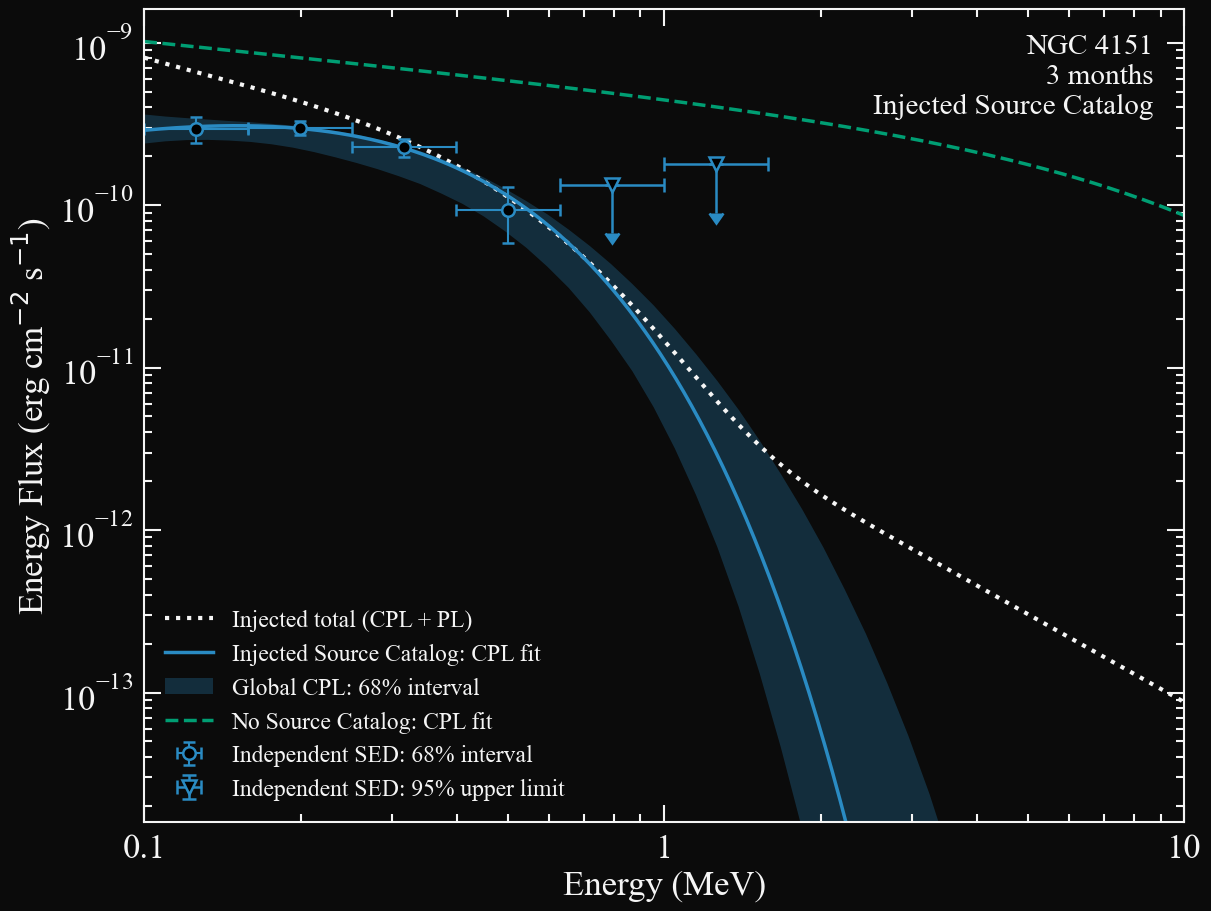

In [42]:
parallel_figure = plot_method_sed(
    "parallel chunks", "NGC4151_parallel_chunks_sed", BLUE,
)


In [ ]:
# Inspect every native SED bin without rerunning the global or SED fits.
# Bin 7 is 1.58–2.51 MeV (one-based numbering). A bin is plotted as an
# upper limit when 1 ≤ TS < 4 or its lower 68% bound reaches zero.
# Bins with TS < 1 are omitted from the plot.
sed = fit_outputs["parallel chunks"]["sed"]
fit = fit_outputs["parallel chunks"]
if (fit.get("catalog file") != str(parallel_catalog_path.resolve())
        or fit.get("catalog sha256") != hashlib.sha256(parallel_catalog_path.read_bytes()).hexdigest()):
    raise RuntimeError("Parallel SED was fitted with the old catalog; rerun its fit cell")
pivot = np.asarray(sed["pivot keV"], dtype=float)
edges = np.asarray(sed["edges keV"], dtype=float)
method_pivot = parallel_model.ngc4151.spectrum.main.composite.piv_1.value
cpl_flux = fitted_cpl_flux(fit, pivot, method_pivot)
injected_at_pivot = np.asarray([spectrum_inj.evaluate_at(e) for e in pivot])
sed_flux = KEV_TO_ERG * pivot**2 * sed["K"]
cpl_energy_flux = KEV_TO_ERG * pivot**2 * cpl_flux
injected_energy_flux = KEV_TO_ERG * pivot**2 * injected_at_pivot
is_detection = (sed["TS"] >= 4) & (sed["K"] > 0) & (
    sed["lower 68"] > 0) & np.isfinite(sed["upper 68"])
has_limit = (~is_detection) & (sed["TS"] >= 1) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0)
status = np.where(
    is_detection, "68% point",
    np.where(has_limit, "95% limit",
             np.where(sed["TS"] < 1, "omitted: TS < 1", "omitted: no finite limit")),
)
diagnostic = pd.DataFrame({
    "bin": np.arange(1, len(pivot) + 1),
    "low MeV": edges[:-1] / 1000,
    "high MeV": edges[1:] / 1000,
    "TS": sed["TS"],
    "SED energy flux erg/cm²/s": sed_flux,
    "CPL energy flux erg/cm²/s": cpl_energy_flux,
    "injected energy flux erg/cm²/s": injected_energy_flux,
    "SED/CPL": np.divide(sed_flux, cpl_energy_flux, out=np.full_like(sed_flux, np.nan), where=cpl_energy_flux > 0),
    "status": status,
})
display(diagnostic)
print("TS < 1 bins:", diagnostic.loc[diagnostic["TS"] < 1, ["bin", "TS", "status"]].to_string(index=False))


### GTI normalization-fit catalog

In [ ]:
# Refresh point and diffuse spectral integration in an already-running kernel.
refresh_dc4_response_integrators()

# This cell is independent: a failure here leaves the parallel result intact.
fit_outputs["fitted normalization"] = fit_catalog_method("fitted normalization")
gc.collect()


Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_fitted_normalization_sed_black.png and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_fitted_normalization_sed_transparent.png


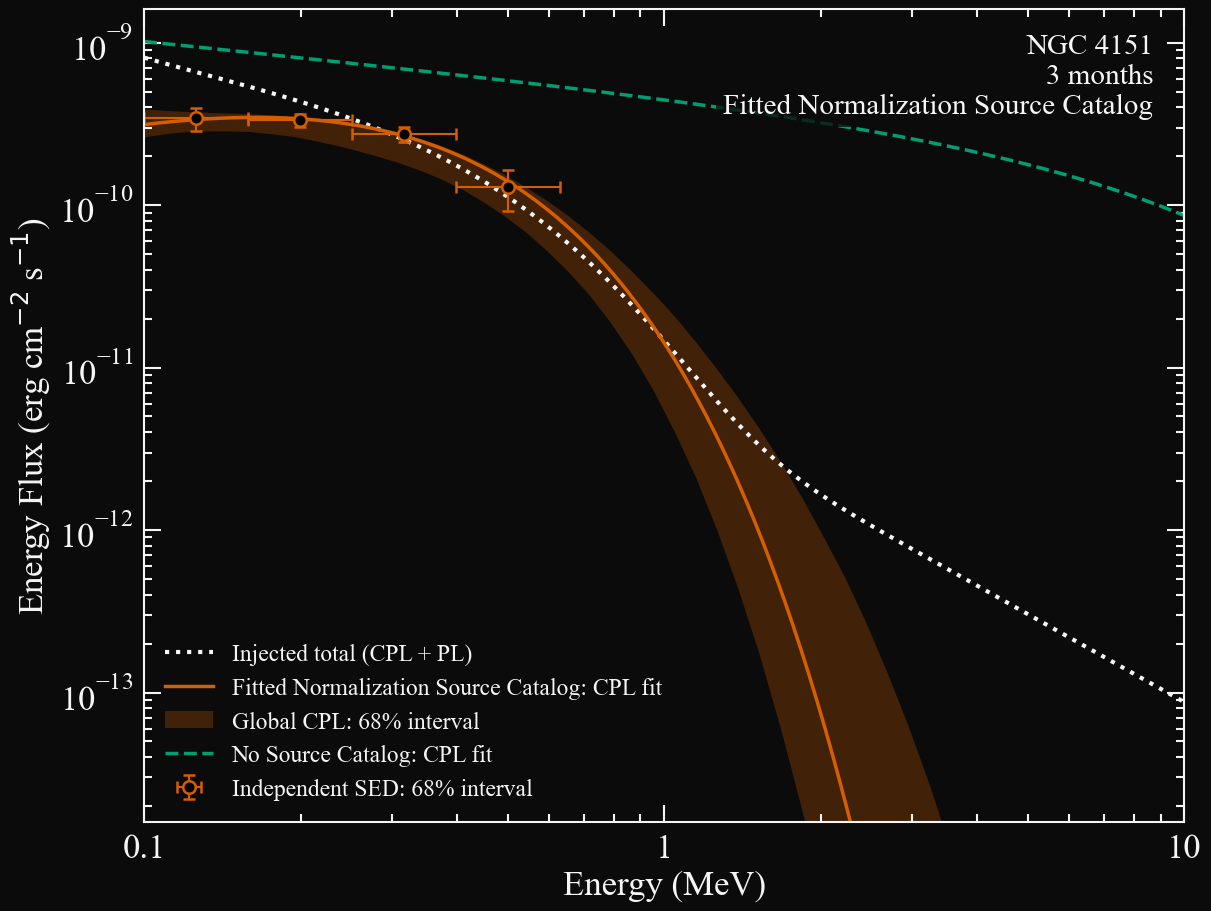

In [43]:
normalization_figure = plot_method_sed(
    "fitted normalization", "NGC4151_fitted_normalization_sed", ORANGE,
)


## Fitted parameters and 68% intervals without refitting

Run only the next cell to display fit values and any saved marginal 68%
parameter intervals. It does not create responses or run a likelihood fit.
Older fits saved only central values, so their uncertainty entries read
‘68% unavailable’ until that method's fit is rerun. The CPL curve band
cannot recover the individual parameter errors. Catalog provenance is
checked against the current YAML files.

To recover numerical intervals for a previously saved fit, rerun the helper-definition
cell above, then call `fit_catalog_method("parallel chunks", run_sed=False)` or
`fit_catalog_method("fitted normalization", run_sed=False)` in a new cell.
This repeats only that method’s global likelihood fit, saves its intervals, and
skips the independent SED extraction. Rerun the table cell afterward. The
model/data setup must still be present in the live kernel.


In [44]:
# Display available global-fit parameters without rerunning any fit.
# When a method fit is run, it saves its small JSON parameter summary before
# starting the slower independent SED fit. A current kernel can also show
# results from fits performed before this summary file was added.
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display

summary_dir = globals().get("notebook_dir", Path.cwd().resolve())
if not (summary_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (summary_dir, *summary_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    summary_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"

catalogs = {
    "parallel chunks": summary_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml",
    "fitted normalization": summary_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml",
}
active_results = globals().get("global_fit_outputs", {})
if not active_results:
    active_results = globals().get("fit_outputs", {})
def format_saved_parameter(record, label, spec):
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return f"{value:{spec}} (−{value-lower:{spec}}/+{upper-value:{spec}})"


import numpy as np
rows = []
for method, catalog in catalogs.items():
    record = active_results.get(method)
    origin = "current kernel" if record is not None else "saved JSON"
    if record is None:
        parameter_file = summary_dir / "plots" / f"NGC4151_{method.replace(' ', '_')}_global_fit.json"
        if parameter_file.is_file():
            record = json.loads(parameter_file.read_text())
    if record is None:
        previous_file = summary_dir / "plots" / "NGC4151_previous_global_fits.json"
        if previous_file.is_file():
            record = json.loads(previous_file.read_text()).get(method)
            origin = "previous saved notebook fit"
    if record is None:
        continue
    current_hash = hashlib.sha256(catalog.read_bytes()).hexdigest()
    revision = record.get("analysis revision", "")
    if revision.startswith("previous saved notebook run"):
        provenance = "previous fit: rerun needed for GTI/code changes"
    elif record.get("catalog file") != str(catalog.resolve()):
        provenance = "older or unknown catalog"
    elif record.get("catalog sha256") != current_hash:
        provenance = "catalog contents changed or hash unrecorded"
    elif revision == "GTI-native-knot-v1":
        provenance = "current catalog"
    else:
        provenance = "catalog matches; code revision unrecorded"
    rows.append({
        "fit": method,
        "K (ph cm⁻² s⁻¹ keV⁻¹), 68%": format_saved_parameter(record, "K", ".3g"),
        "index, 68%": format_saved_parameter(record, "index", ".3g"),
        "xc (keV), 68%": format_saved_parameter(record, "xc (keV)", ".3g"),
        "background (Hz), 68%": format_saved_parameter(record, "background (Hz)", ".4g"),
        "log likelihood": record.get("log likelihood"),
        "covariance valid": record.get("covariance valid"),
        "source": origin,
        "catalog status": provenance,
    })

one_source = globals().get("one_source_fit")
one_source_origin = "current kernel"
if one_source is None:
    one_source_file = summary_dir / "plots" / "NGC4151_one_source_global_fit.json"
    if one_source_file.is_file():
        one_source = json.loads(one_source_file.read_text())
        one_source_origin = "saved JSON"
    else:
        previous_file = summary_dir / "plots" / "NGC4151_previous_global_fits.json"
        if previous_file.is_file():
            one_source = json.loads(previous_file.read_text()).get("NGC 4151 only")
            one_source_origin = "previous saved notebook fit"
if one_source is not None:
    rows.append({
        "fit": "NGC 4151 only",
        "K (ph cm⁻² s⁻¹ keV⁻¹), 68%": format_saved_parameter(one_source, "K", ".3g"),
        "index, 68%": format_saved_parameter(one_source, "index", ".3g"),
        "xc (keV), 68%": format_saved_parameter(one_source, "xc (keV)", ".3g"),
        "background (Hz), 68%": format_saved_parameter(one_source, "background (Hz)", ".4g"),
        "log likelihood": None,
        "covariance valid": None,
        "source": one_source_origin,
        "catalog status": "no source catalog",
    })

if rows:
    table = pd.DataFrame(rows)
    table["log likelihood"] = table["log likelihood"].map(
        lambda value: f"{value:.6f}" if pd.notna(value) else "—"
    )
    display(table)
else:
    print("No fit results are available in this kernel or saved parameter JSON files.")


,fit,"K (ph cm⁻² s⁻¹ keV⁻¹), 68%","index, 68%","xc (keV), 68%","background (Hz), 68%",log likelihood,covariance valid,source,catalog status
0,parallel chunks,1.5e-05 (68% unavailable),-1.12 (68% unavailable),170 (68% unavailable),25.53 (68% unavailable),118228904.532378,True,current kernel,catalog matches; code revision unrecorded
1,fitted normalization,1.73e-05 (68% unavailable),-1.03 (68% unavailable),169 (68% unavailable),25.59 (68% unavailable),118228894.836745,True,current kernel,catalog matches; code revision unrecorded
2,NGC 4151 only,1.28e-05 (68% unavailable),-2.32 (68% unavailable),1e+04 (68% unavailable),26.52 (68% unavailable),—,None,current kernel,no source catalog
